# Credit Card Fraud Detection

In [19]:
# Importing Libraries
import warnings
warnings.filterwarnings('ignore')
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.metrics import classification_report 
from sklearn.preprocessing import LabelEncoder

# Data Collection
df_train = pd.read_csv("Fraud_Train_Data.csv")
df_test = pd.read_csv("Fraud_Test_Data.csv")

display(df_train.head(2))
display(df_test.head(2))

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0


Cleaned Data Saved


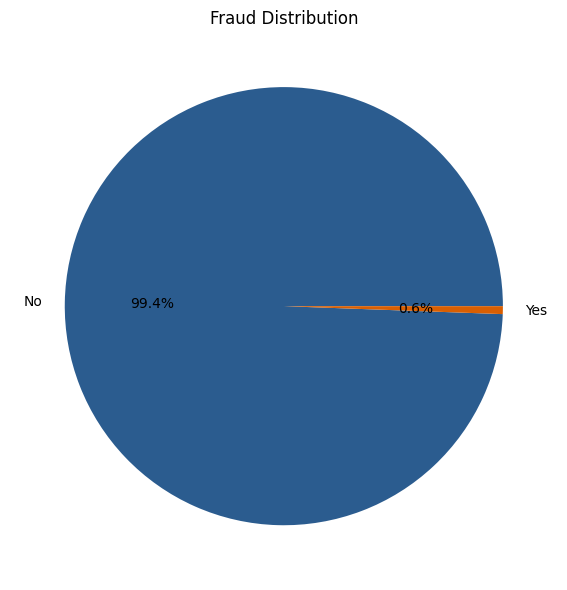

In [20]:
# Data Preprocessing
no_value_cols = ['Unnamed: 0', 'cc_num', 'first', 'last', 'street', 'city', 
                'state', 'zip', 'dob', 'trans_num', 'trans_date_trans_time']

cat_cols = ["merchant", "category", "gender", "job"]

df_train.drop(columns = no_value_cols, inplace=True)
df_test.drop(columns = no_value_cols, inplace=True)

for col in cat_cols:
    le = LabelEncoder()
    df_train[col] = le.fit_transform(df_train[col])  
    df_test[col] = le.fit_transform(df_test[col])

# Save cleaned data
df_train.to_csv("Fraud_Train_Cleaned_Data.csv")
df_test.to_csv("Fraud_Test_Cleaned_Data.csv")
print("Cleaned Data Saved")


# Data Visualization
fraud_counts = df_train["is_fraud"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(fraud_counts, labels=["No", "Yes"], autopct="%0.1f%%", colors=['#2b5c8f', '#d95f02'])
plt.title("Fraud Distribution")
plt.tight_layout() 
plt.show()

In [21]:
# Separate Features and Target
X_train = df_train.drop(columns=["is_fraud"])
Y_train = df_train["is_fraud"]
X_test = df_test.drop(columns=["is_fraud"])
Y_test = df_test["is_fraud"]


# Model Training
model = XGBClassifier(
    scale_pos_weight=(len(Y_train) - sum(Y_train)) / sum(Y_train), 
    random_state=42
)
model.fit(X_train, Y_train)


# Model Evaluation
y_pred = model.predict(X_test)
print("\nClassification Report:\n", classification_report(Y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.28      0.47      0.35      2145

    accuracy                           0.99    555719
   macro avg       0.64      0.73      0.68    555719
weighted avg       1.00      0.99      0.99    555719



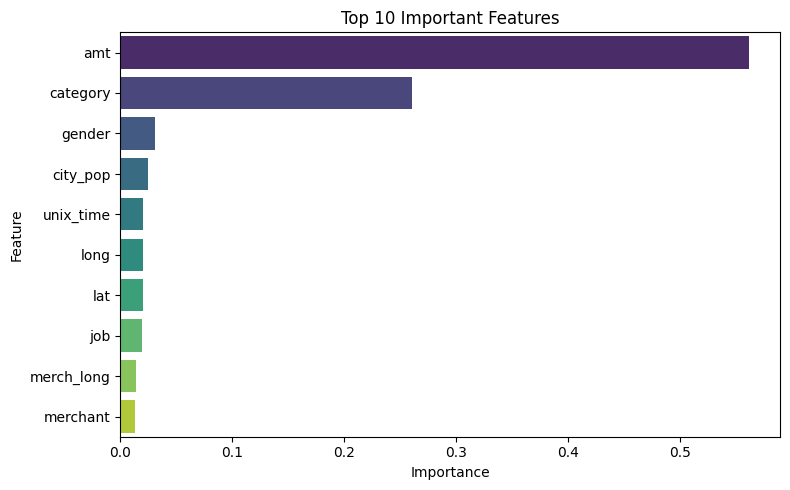

Model saved successfully.


In [22]:
# Feature Importance 
importance = pd.DataFrame({"Feature": X_train.columns, "Importance": model.feature_importances_})
importance = importance.sort_values(by="Importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=importance.head(10), x="Importance", y="Feature", palette="viridis")
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()


# Model Serialization
joblib.dump(model, "Credit_Card_Fraud_Detection.pkl")
print("Model saved successfully.")